# Exploring the data and testing the model

**DSCI 6601 course project: IBM AMLworld HI-Small.**

The question this project answers every day: *which transactions and accounts should an analyst review first, and why?*

* **Part A, exploration (sections 1–8):** the data's structure and quality, and how laundering relates to time, payment type, currency, amount, account connections and the known laundering schemes. Every finding ends with the **decision** it led to in the pipeline. Charts are saved to `outputs/figures/`, and the numbers the course report quotes to `outputs/eda_summary.json`.
* **Part B, the trained model (sections 9–12):** load the model that `make train` saved, score the test days, and look at its results, its reasons, the daily review list and a draft FINTRAC report.

Run `make train` first (it prepares `data/processed/transactions.parquet` and saves the model), then run this notebook top to bottom, or run `make notebook`.

In [1]:
%matplotlib inline
import json
import polars as pl
from IPython.display import display
from src import config, eda
from src.data import parse_patterns, read_accounts
from src.viz import apply_style

apply_style()
pl.Config.set_tbl_rows(20)
config.ensure_dirs()


def show(fig, name):
    """Show the chart here and save it to outputs/figures/."""
    fig.savefig(config.FIGURES / name)
    return fig


df = pl.read_parquet(config.PREPARED)
patterns = parse_patterns(config.PATTERNS_TXT)
accounts = read_accounts(config.ACCOUNTS_CSV)
quality = json.loads((config.OUTPUTS / "data_quality.json").read_text())
df.shape

(5078336, 71)

# Part A: exploring the data

## 1. Structure and quality checks

The three files: transfers (`HI-Small_Trans.csv`), the listed laundering schemes (`HI-Small_Patterns.txt`) and account owners (`HI-Small_accounts.csv`).
Bank codes and some account numbers are digits with leading zeros, so everything is read as text first and only amounts are cast to numbers.

In [2]:
{k: quality[k] for k in ["rows_raw", "exact_duplicates_dropped", "null_cells", "ts_min", "ts_max",
                         "non_positive_amounts", "amount_usd_min", "amount_usd_max", "accounts",
                         "laundering", "laundering_rate", "max_conversion_error_rel",
                         "cross_currency_rows", "cross_currency_laundering",
                         "pattern_attempts", "pattern_transactions", "pattern_transactions_matched"]}

{'rows_raw': 5078345,
 'exact_duplicates_dropped': 9,
 'null_cells': 0,
 'ts_min': '2022-09-01 00:00:00',
 'ts_max': '2022-09-18 16:18:00',
 'non_positive_amounts': 0,
 'amount_usd_min': 9.487666033112179e-05,
 'amount_usd_max': 26558612904.52836,
 'accounts': 515088,
 'laundering': 5177,
 'laundering_rate': 0.0010194284111961084,
 'max_conversion_error_rel': 0.00011594843441401795,
 'cross_currency_rows': 72166,
 'cross_currency_laundering': 0,
 'pattern_attempts': 370,
 'pattern_transactions': 3209,
 'pattern_transactions_matched': 3209}

**Findings.**
* No missing values in any column, and no zero or negative amounts. Missingness therefore needs no imputation (it is neither MCAR nor MAR — there is none).
* 9 rows are exact duplicates (all tiny, non-laundering Bitcoin transfers). **Decision:** drop them.
* Each currency has one fixed exchange rate: once both sides of a currency-changing transfer are converted, they agree to within about 0.01% (rounding of small amounts). **Decision:** convert every amount to US dollars with these rates.
* 5,177 of 5,078,336 transfers are laundering (0.10%). **Decision:** never use accuracy; use F1 on the laundering class and the area under the precision–recall curve.
* All 3,209 transfers in the patterns file match a row in the transfer file, so 62% of laundering has a known scheme type.

In [3]:
rates = quality["usd_rates"]
pl.DataFrame({"currency": list(rates), "usd_per_unit": list(rates.values())}).sort("usd_per_unit")

currency,usd_per_unit
str,f64
"""Yen""",0.009488
"""Ruble""",0.012853
"""Rupee""",0.013616
"""Mexican Peso""",0.047297
"""Yuan""",0.149307
"""Brazil Real""",0.177101
"""Saudi Riyal""",0.266588
"""Shekel""",0.296121
"""Australian Dollar""",0.707814


## 2. Time: when does laundering happen?

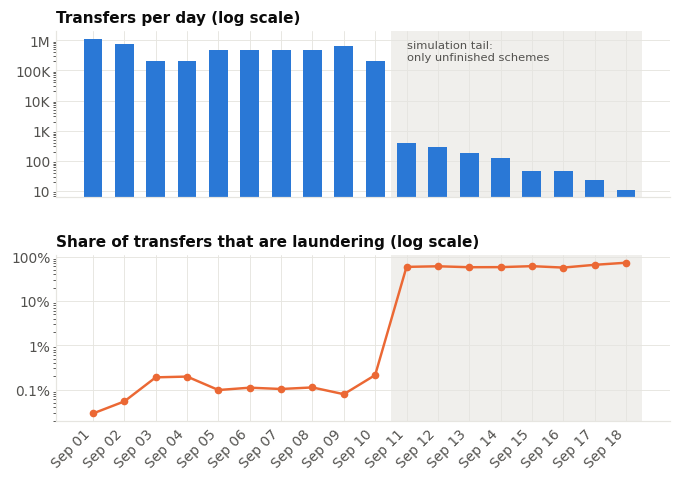

In [4]:
daily = eda.daily_profile(df)
show(eda.fig_daily(daily, config.LAST_CORE_DAY), "eda_01_daily.png");

In [5]:
display(daily)

day,transfers,laundering,rate
date,u32,i64,f64
2022-09-01,1114919,322,0.000289
2022-09-02,754449,408,0.000541
2022-09-03,207382,391,0.001885
2022-09-04,207430,407,0.001962
2022-09-05,482650,471,0.000976
2022-09-06,482089,531,0.001101
2022-09-07,482750,497,0.00103
2022-09-08,482771,539,0.001116
2022-09-09,654463,514,0.000785


**Finding.** Days 1–10 hold 99.98% of transfers. After 10 September the simulator stops making normal payments and only finishes laundering schemes already under way: the last eight days have 1,108 transfers, 57–73% of them laundering.
**Decision:** split by time (60/20/20, cut at minute boundaries so no minute is shared), and report test results for the normal days and for these tail days **separately**, because the tail would make any model look better than it is.

## 3. Payment type and currency: signals that are too clean

fmt,transfers,laundering,share_of_transfers,share_of_laundering,rate
str,u32,i64,f64,f64,f64
"""Cheque""",1864331,324,0.367115,0.062585,0.000174
"""Credit Card""",1323324,206,0.260582,0.039791,0.000156
"""ACH""",600793,4483,0.118305,0.865946,0.007462
"""Cash""",490891,108,0.096664,0.020862,0.00022
"""Reinvestment""",481056,0,0.094727,0.0,0.0
"""Wire""",171855,0,0.033841,0.0,0.0
"""Bitcoin""",146086,56,0.028767,0.010817,0.000383


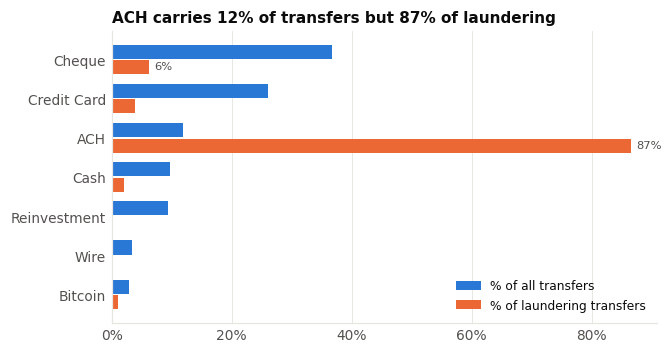

In [6]:
fmt = eda.category_profile(df, "fmt")
display(fmt)
show(eda.fig_shares(fmt, "fmt", "ACH carries 12% of transfers but 87% of laundering"), "eda_02_payment_format.png");

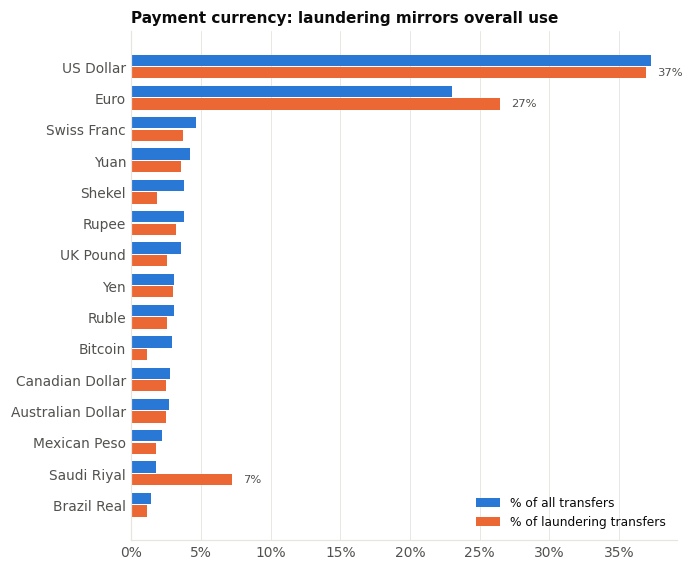

In [7]:
cur = eda.category_profile(df, "cur_paid")
show(eda.fig_shares(cur, "cur_paid", "Payment currency: laundering mirrors overall use"), "eda_03_currency.png");

In [8]:
pairs = eda.currency_pairs(df)
pairs.group_by("changes_currency").agg(pl.col("transfers").sum(), pl.col("laundering").sum(), pl.len().alias("currency_pairs"))

changes_currency,transfers,laundering,currency_pairs
bool,u32,i64,u32
true,72166,0,201
false,5006170,5177,15


In [9]:
pairs.filter(pl.col('changes_currency')).head(10)

cur_paid,cur_recv,transfers,laundering,changes_currency
str,str,u32,i64,bool
"""US Dollar""","""Euro""",15838,0,true
"""Euro""","""US Dollar""",11060,0,true
"""Yuan""","""US Dollar""",6675,0,true
"""US Dollar""","""Yuan""",2547,0,true
"""US Dollar""","""Swiss Franc""",2507,0,true
"""US Dollar""","""UK Pound""",2489,0,true
"""US Dollar""","""Rupee""",2310,0,true
"""US Dollar""","""Shekel""",2204,0,true
"""US Dollar""","""Yen""",2027,0,true


**Findings.** ACH carries 12% of all transfers but 87% of laundering; wire transfers and reinvestments are never laundering. No laundering transfer changes currency: all 201 currency-changing pairs (out of 216 pairs seen; 72,166 transfers) have zero laundering, while all 5,177 laundering transfers sit on same-currency pairs.
Currency shares for laundering roughly follow overall use (Saudi riyal is the one over-represented currency).
These are properties of the simulator, not of real laundering.
**Decision:** keep payment type and currency as encoded features, but train the selected model again *without* them (and without the currency-change flag) to measure how much the score depends on these shortcuts. Currency could also stand in for country, which is another reason to check.

## 4. Amounts and time of day

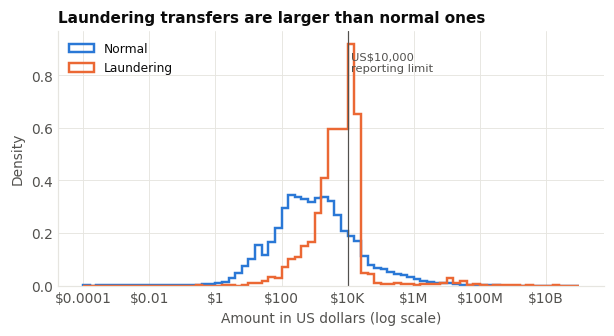

In [10]:
show(eda.fig_amount(df), "eda_04_amount.png");

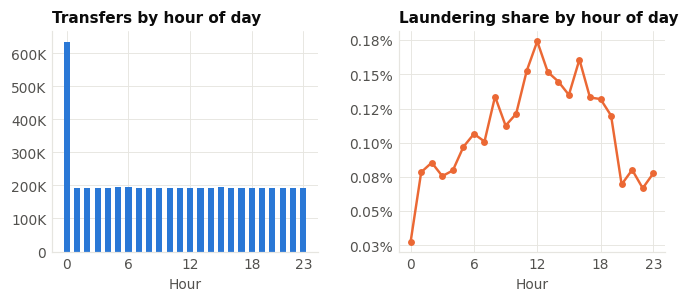

In [11]:
show(eda.fig_hour(df), "eda_05_hour.png");

**Findings.** Amounts span 10⁻⁴ to 2.7×10¹⁰ US dollars, so the scale is extremely skewed; laundering transfers are larger (median about US$5,900 vs US$890). Only 149 laundering transfers (2.9%) sit just below the US$10,000 reporting limit, so classic "structuring" is rare here. The laundering share is about twice as high in working hours (0.15–0.17% between 11:00 and 16:00) as in the evening (about 0.07%), and lowest in the midnight hour (0.03%).
**Decision:** use log(amount) (and a signed log + scaling for logistic regression); keep the just-below-limit flag as a rule and a feature; keep hour of day.

## 5. Hub accounts and the shape of the network

We build the whole-period graph of who paid whom (accounts as nodes, distinct payer→payee pairs as edges) and compute each account's number of distinct counterparties and its PageRank.
This graph sees the future, so it is used **only for exploration**, never as a model input.

In [12]:
stats = eda.account_graph_stats(df)
hubs = eda.hub_summary(stats)
hubs

{'accounts': 422734,
 'top_k': 422,
 'out_degree_top_involved_rate': 0.06872037914691943,
 'out_degree_rest_involved_rate': 0.014984182310708671,
 'out_degree_top_share_of_transfers': 0.05609450507719421,
 'in_degree_top_involved_rate': 0.11137440758293839,
 'in_degree_rest_involved_rate': 0.01494155979465419,
 'in_degree_top_share_of_transfers': 0.04897413131440094,
 'pagerank_top_involved_rate': 0.07819905213270142,
 'pagerank_rest_involved_rate': 0.01497471064047434,
 'pagerank_top_share_of_transfers': 0.03258479150565039}

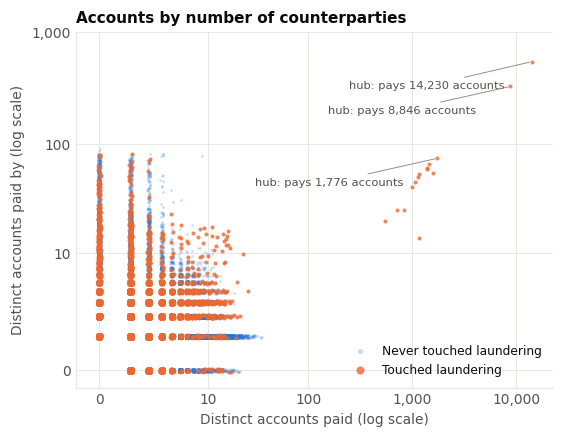

In [13]:
show(eda.fig_hubs(stats), "eda_06_hubs.png");

In [14]:
keys = pl.read_parquet(config.ACCOUNT_KEYS).with_row_index("account").with_columns(pl.col("account").cast(pl.Int32))
stats.sort("pagerank", descending=True).head(10).join(keys, on="account", how="left")

account,transfers,involved,out_degree,in_degree,pagerank,key
i32,u32,i8,u32,u32,f64,str
515073,169756,1,14230,545,0.000426,"""070_100428660"""
199078,83,0,1,82,0.000287,"""013145_80640B300"""
118164,83,0,1,82,0.000287,"""007042_80640FE10"""
350450,71,0,1,69,0.000274,"""0244187_8107D3970"""
45204,74,0,1,73,0.000274,"""0021615_80E6D9980"""
222629,69,0,1,68,0.000274,"""0143496_8107A0740"""
146586,79,0,1,77,0.000271,"""01132_80A444B70"""
87857,52,0,1,51,0.000262,"""003_80E6E1760"""
98667,71,0,1,70,0.000262,"""004600_8029BFDC0"""


**Findings.** Most accounts deal with only a handful of others. A few bank-070 hub accounts pay more than 1,000 (one pays 14,230) accounts, and they too took part in laundering.
Among the top 0.1% of accounts by number of payers, 11% touched laundering, against 1.5% of the rest: collection hubs are riskier.
**Decision:** give the model each account's *recent* fan-in and fan-out (distinct counterparties in the last hour, day and week, computed only from earlier transfers) instead of whole-period centrality, which would leak the future.

## 6. The known laundering schemes

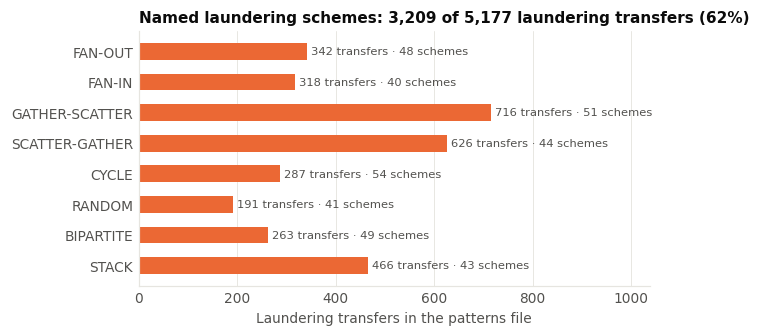

In [15]:
show(eda.fig_typology_counts(patterns, int(df['is_laundering'].sum())), "eda_07_typology_counts.png");

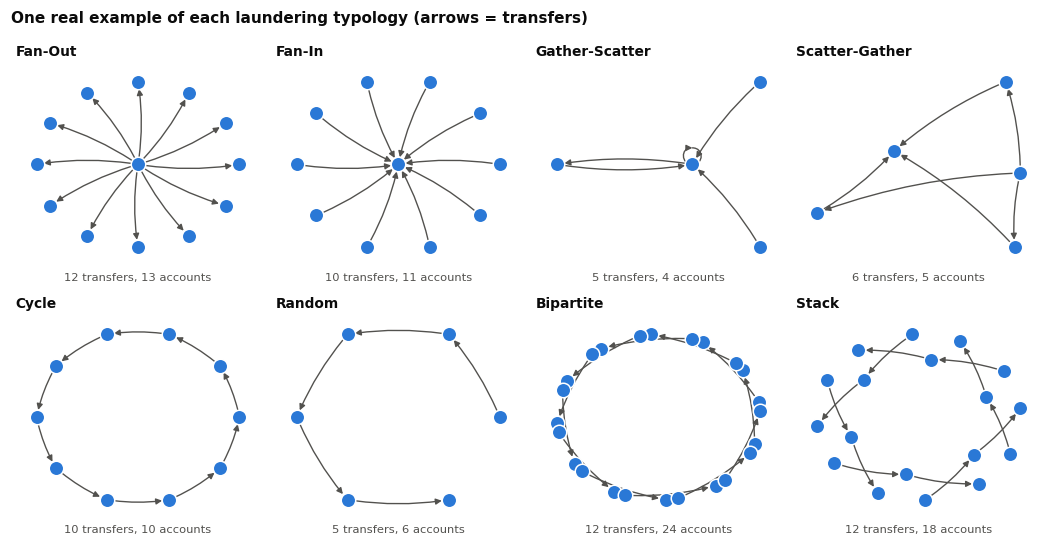

In [16]:
show(eda.fig_typology_examples(patterns), "eda_08_typology_examples.png");

**Findings.** The 370 listed schemes are spread evenly over eight shapes. Fan-out and fan-in are one account paying, or being paid by, many; cycles return money to where it started; scatter-gather and stack schemes send money along several parallel routes; random walks pass money on without returning it.
**Decision:** add features that can see these shapes as they happen: distinct counterparties per window (fan-in/out), *has the receiver already paid the sender* and *does this transfer close a three-step loop* (cycles), *how many accounts already link sender to receiver in two steps* (parallel routes), and *minutes since the sender last received money* (pass-through speed).

## 7. How each warning sign relates to laundering

signal,transfers,laundering_rate,lift,coverage
str,i64,f64,f64,f64
"""Changes currency""",72166,0.0,0.0,0.0
"""Same bank on both sides""",691251,0.000149,0.146165,0.019896
"""Sender already paid 5+ account…",895960,0.001124,1.102514,0.194514
"""Just below US$10,000""",46415,0.00321,3.148989,0.028781
"""Sender pays this receiver for …",1250579,0.003397,3.332089,0.820552
"""Pays on about what came in (24…",59651,0.005264,5.163631,0.060653
"""Receiver already paid by 5+ ac…",59786,0.006791,6.661466,0.078424
"""ACH payment""",600793,0.007462,7.319597,0.865946
"""Receiver had already paid the …",4842,0.066088,64.828871,0.061812


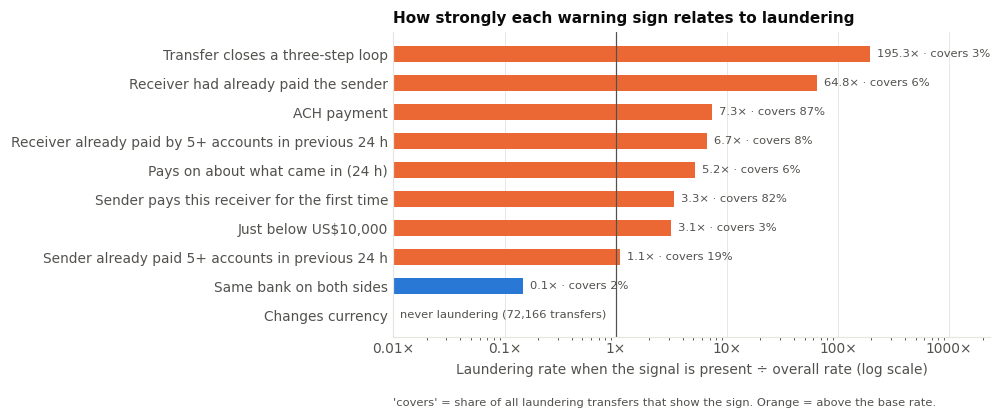

In [17]:
lift = eda.signal_lift(df)
display(lift)
show(eda.fig_signal_lift(lift), "eda_09_signal_lift.png");

**Findings.** Loops are the sharpest signal: a transfer that closes a three-step loop is laundering about 20% of the time (195 times the base rate), and a payment back to an account that paid you is 65 times the base rate. But each covers only a few percent of laundering.
Paying someone for the first time covers 82% of laundering at 3.3 times the base rate. The classic warning-sign rules are weak on their own: a sender that had already paid 5+ accounts that day is barely above the base rate (1.1 times), and a receiver already paid by 5+ accounts reaches 6.7 times but covers only 8% of laundering.
**Decision:** no single rule is enough, so we combine these signals in a learned model; the warning-sign rules stay as the baseline to beat.

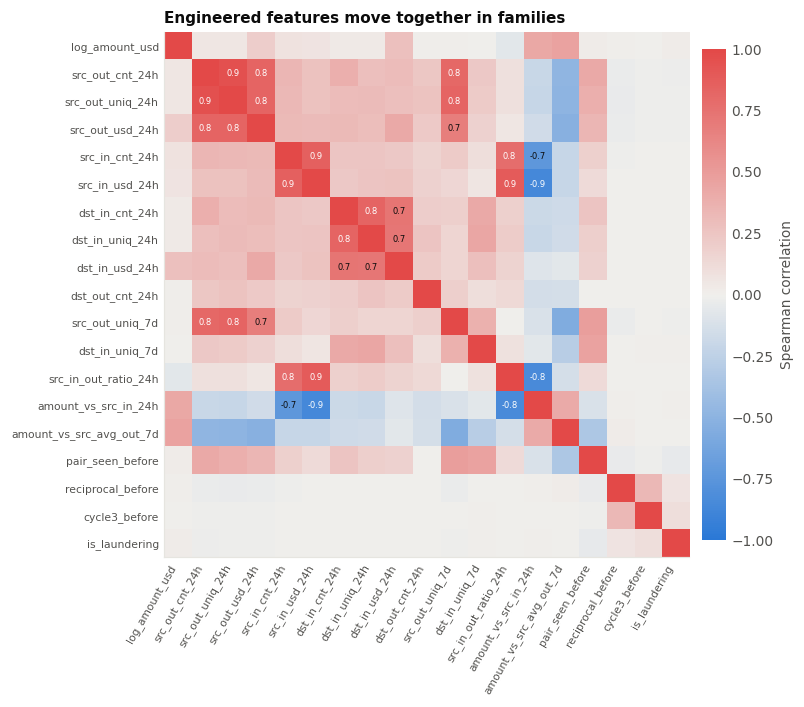

In [18]:
corr, names = eda.spearman_matrix(df)
show(eda.fig_correlation(corr, names), "eda_10_correlation.png");

**Finding.** The engineered features come in correlated families (counts, distinct counterparties and dollar totals for the same window move together, ρ ≈ 0.7–0.9), and every single feature has a weak rank correlation with the label.
**Decision:** use tree models that cope with correlated inputs and interactions; give logistic regression an L1 option so it can drop redundant features.

## 8. Account owners: a fairness check

entity_type,transfers,laundering,rate
str,u32,i64,f64
"""Sole Proprietorship""",1790826,1552,0.000867
"""Partnership""",1781365,1805,0.001013
"""Corporation""",1409467,1783,0.001265
"""Country""",91852,31,0.000337
"""Individual""",4323,6,0.001388
"""Direct""",503,0,0.0


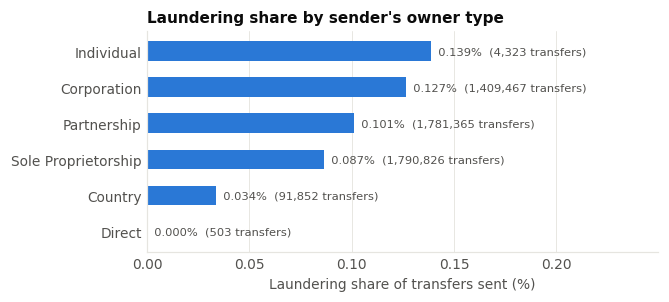

In [19]:
ent = eda.entity_profile(df, accounts)
display(ent)
show(eda.fig_entity(ent), "eda_11_entity_type.png");

**Finding.** Laundering rates differ little between owner types (corporations 0.13%, partnerships 0.10%, sole proprietors 0.09%); individuals are rare in this file.
**Decision:** account and bank identifiers, bank country and owner type are *not* model inputs, so the model judges behaviour rather than who someone is or where they bank. Currency remains the one possible stand-in for country, which the shortcut ablation checks.

**Saving the numbers.** The course report quotes these exploration numbers, so we save them to `outputs/eda_summary.json`.

In [20]:
top_hubs = stats.sort("pagerank", descending=True).head(10).join(keys, on="account", how="left")
summary = {
    "daily": daily.with_columns(pl.col("day").cast(pl.Utf8)).to_dicts(),
    "payment_format": fmt.to_dicts(),
    "currency": cur.to_dicts(),
    "currency_pairs": {
        "pairs": pairs.height,
        "cross_currency_pairs": int(pairs["changes_currency"].sum()),
        "cross_currency_transfers": int(pairs.filter(pl.col("changes_currency"))["transfers"].sum()),
        "cross_currency_laundering": int(pairs.filter(pl.col("changes_currency"))["laundering"].sum()),
        "top_cross_pairs": pairs.filter(pl.col("changes_currency")).head(10).to_dicts(),
    },
    "hubs": hubs,
    "top_pagerank_accounts": top_hubs.to_dicts(),
    "signal_lift": lift.to_dicts(),
    "entity_type": ent.to_dicts(),
    "typology": patterns.group_by("typology").agg(pl.col("attempt_id").n_unique().alias("attempts"), pl.len().alias("transfers")).sort("typology").to_dicts(),
    "corr_with_label": dict(zip(names, [float(c) for c in corr[-1]])),
    **eda.summary_numbers(df),
}
(config.OUTPUTS / "eda_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("saved outputs/eda_summary.json")

saved outputs/eda_summary.json


# Part B: load the trained model and test it

This part needs `make train` first, which saves the model to `model/`. The model and its alert threshold were fixed on the training and validation days. Here we only score the test days, exactly as `make evaluate` does, and look at the results: nothing below changes the model.

In [21]:
from src.evaluate import load_model, result_figure, score_test_days

bundle = load_model()
print(f"{bundle['family']} {bundle['params']}: alert threshold {bundle['threshold']:.3f}, {len(bundle['features'])} features")
scored, metrics = score_test_days(bundle)
scored.shape

xgboost {'learning_rate': 0.1, 'max_depth': 6, 'scale_pos_weight': 1}: alert threshold 0.280, 55 features


(1015876, 69)

## 9. How well does it flag laundering on the test days?

The normal test days (8 Sep 16:12 to 10 Sep) are the fair test; the tail days (11 to 18 Sep) are mostly laundering, so they are reported apart. The warning-sign rules are the baseline, tuned on the validation days just like the model's threshold.

In [22]:
parts = {
    "Model, normal days": metrics["test"]["core_days"],
    "Model, incl. tail days": metrics["test"]["all"],
    "Warning-sign rules, normal days": metrics["rules"]["test"]["core_days"],
}
pl.DataFrame(
    [{"": name, **{k: round(m[k], 3) for k in ("f1", "precision", "recall", "pr_auc")}, "alerts": m["tp"] + m["fp"], "laundering caught": m["tp"]}
     for name, m in parts.items()]
)

,f1,precision,recall,pr_auc,alerts,laundering caught
str,f64,f64,f64,f64,i64,i64
"""Model, normal days""",0.499,0.847,0.353,0.498,477,404
"""Model, incl. tail days""",0.646,0.914,0.499,0.675,983,898
"""Warning-sign rules, normal day…",0.001,0.001,0.002,0.001,2119,2


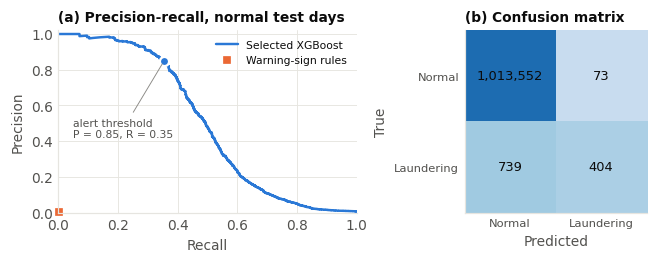

In [23]:
show(result_figure(scored, metrics), "model_result_test.png");

**Reading it.** (a) The curve shows every precision/recall trade-off the score allows; the dot is the alert threshold chosen on validation days, and the rules' square sits near the origin. (b) The confusion matrix at that threshold: few false alarms, but most normal-day laundering is still missed.

## 10. Why was a transfer flagged?

For the highest-scoring alerts, the three features that pushed the score up the most (TreeSHAP), in plain English. These are the same reasons the AI assistant receives in its evidence.

In [24]:
from ai_agent.evidence import describe_reason
from src.explain import top_reasons
from src.models import contributions

alerts = scored.filter(pl.col("score") >= bundle["threshold"]).sort("score", descending=True).head(5)
contrib, feature_names = contributions(bundle["model"], alerts.select(bundle["features"]).to_pandas())
for row, reasons in zip(alerts.iter_rows(named=True), top_reasons(contrib, feature_names, k=3)):
    truth = f"LAUNDERING ({row['typology'] or 'scheme not listed'})" if row["is_laundering"] else "normal"
    print(f"{row['ts']}  {row['src_key']} -> {row['dst_key']}  US${row['amount_usd']:,.2f}  score {row['score']:.3f}  truth: {truth}")
    for f in reasons:
        print("    -", describe_reason(f, row))

2022-09-09 15:59:00  0150240_812D22980 -> 0048309_811C599A0  US$19,758.47  score 1.000  truth: LAUNDERING (FAN-OUT)
    - it was paid by ACH
    - the receiver had earlier paid the sender (money going back and forth)
    - it was paid in Saudi Riyal
2022-09-13 12:50:00  0149345_812D1AC00 -> 0119_81235E8B0  US$12,419.94  score 0.999  truth: normal
    - it was paid by ACH
    - the receiver had been paid by 12 different accounts in the previous 7 days
    - the amount was US$12,419.94
2022-09-11 08:05:00  018200_803616220 -> 021258_8028E8460  US$15,291.64  score 0.999  truth: LAUNDERING (SCATTER-GATHER)
    - it was paid by ACH
    - the receiver had been paid by 7 different accounts in the previous 7 days
    - the amount was US$15,291.64
2022-09-08 23:38:00  0150240_812D22980 -> 0222_811B83280  US$14,213.33  score 0.999  truth: LAUNDERING (FAN-IN)
    - it was paid by ACH
    - the receiver had earlier paid the sender (money going back and forth)
    - it was paid in Saudi Riyal
2022-

## 11. The daily review list

Transfer scores roll up to one score per account per day (its riskiest transfer). An analyst reviews the top 100 accounts each day: what share of them are truly involved in laundering, ranked by the model and by the rules?

In [25]:
from src.accounts import daily_review_lists

acc, table, _ = daily_review_lists(scored)
table.filter(pl.col("day") <= pl.lit(config.LAST_CORE_DAY).str.to_date()).pivot(on="ranker", index="day", values="precision")

day,model,rules
date,f64,f64
2022-09-08,0.89,0.09
2022-09-09,1.0,0.14
2022-09-10,0.97,0.08


## 12. A draft FINTRAC report

`make evaluate` ends by having the AI assistant draft a report for each day's top accounts, then checking each draft's format and numbers. Here is the first case, written by Gemini (or Claude) if that has been run with a key in `ai_agent/.env`, otherwise by the template.

In [26]:
from IPython.display import Markdown
from ai_agent.checks import validate_report

drafters = [d for d in ("gemini", "claude", "template") if (config.FINTRAC_DIR / d / "summary.json").exists()]
cases = sorted((config.FINTRAC_DIR / drafters[0]).glob("STR-*.json")) if drafters else []
if drafters and cases:
    evidence = json.loads(cases[0].read_text())
    draft = cases[0].with_suffix(".md").read_text()
    check = validate_report(draft, evidence)
    print(f"drafted by: {drafters[0]} | format ok: {check.format_ok} | numbers ok: {check.numbers_ok} {check.unsupported_numbers}")
    display(Markdown(draft))
else:
    print("No drafts yet: run `make evaluate`.")

drafted by: gemini | format ok: True | numbers ok: False ['46']


# DRAFT Suspicious Transaction Report - for analyst review
## 1. Subject
* The subject of this report is a corporate account holder with account ID 0222_811B83280 at bank code 0222.
* This review was initiated on 2022-09-08 under case ID STR-20220908-001.

## 2. Transactions of concern
* On 2022-09-08 at 22:52, the account sent an ACH transfer of 10067.68 USD in Saudi Riyal to counterparty 0150240_812D22980.
* On 2022-09-08 at 23:38, the account received an ACH transfer of 14213.33 USD in Saudi Riyal from the same counterparty, 0150240_812D22980.
* In total for the day, the account engaged in 4 transfers with 3 distinct counterparties, consisting of 2 sent transfers totaling 10196.57 USD and 2 received transfers totaling 15557.88 USD.

## 3. Grounds for suspicion
* Rapid reciprocal ACH transfers occurred between the subject and counterparty 0150240_812D22980 within approximately 46 minutes.
* The receiver had earlier paid the sender, resulting in funds moving back and forth in Saudi Riyal, which may indicate layering or circular transaction patterns without an apparent business purpose.

## 4. Model explanation
* The account generated an overall risk score of 0.999, exceeding the alert threshold of 0.28 and ranking 1 out of a daily review list size of 100.
* Specific risk factors identified for the highest-scoring transfer (2022-09-08 23:38, transfer score 0.999) include that it was paid by ACH, the receiver had earlier paid the sender (money going back and forth), and it was paid in Saudi Riyal.

## 5. Recommended action
* Review the business relationship, transaction rationale, and supporting documentation regarding counterparty 0150240_812D22980.
* Determine whether to file an STR with FINTRAC or apply enhanced transaction monitoring to account 0222_811B83280.